In [1]:
import os
import numpy as np
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt

DATA_DIR = os.path.join("..", "data", "processed")
MODELS_DIR = os.path.join("..", "models")

# Charger les données de test
X_test = np.load(os.path.join(DATA_DIR, "X_test.npy"))
y_test = np.load(os.path.join(DATA_DIR, "y_test.npy"))
X_test = X_test[..., np.newaxis]  # (N, 224, 224, 1) pour le CNN simple

# Version RGB pour MobileNet
X_test_rgb = np.repeat(X_test, 3, axis=-1)
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
X_test_mnv2 = preprocess_input(X_test_rgb * 255.0)

# Charger les deux modèles
model_cnn = keras.models.load_model(os.path.join(MODELS_DIR, "model_v1_simple_cnn.keras"))
model_tl = keras.models.load_model(os.path.join(MODELS_DIR, "model_v2_mobilenet_tl.keras"))

print("X_test:", X_test.shape)
print("X_test_rgb (mobilenet):", X_test_mnv2.shape)
print("y_test:", y_test.shape)
print("\nModèles chargés avec succès.")

X_test: (624, 224, 224, 1)
X_test_rgb (mobilenet): (624, 224, 224, 3)
y_test: (624,)

Modèles chargés avec succès.


In [2]:
print("=== CNN Simple ===")
test_loss_cnn, test_acc_cnn = model_cnn.evaluate(X_test, y_test, verbose=0)
print(f"Test Accuracy: {test_acc_cnn:.4f}")
print(f"Test Loss: {test_loss_cnn:.4f}")

print("\n=== MobileNetV2 (Transfer Learning) ===")
test_loss_tl, test_acc_tl = model_tl.evaluate(X_test_mnv2, y_test, verbose=0)
print(f"Test Accuracy: {test_acc_tl:.4f}")
print(f"Test Loss: {test_loss_tl:.4f}")

=== CNN Simple ===
Test Accuracy: 0.7821
Test Loss: 1.3001

=== MobileNetV2 (Transfer Learning) ===
Test Accuracy: 0.8446
Test Loss: 0.8876


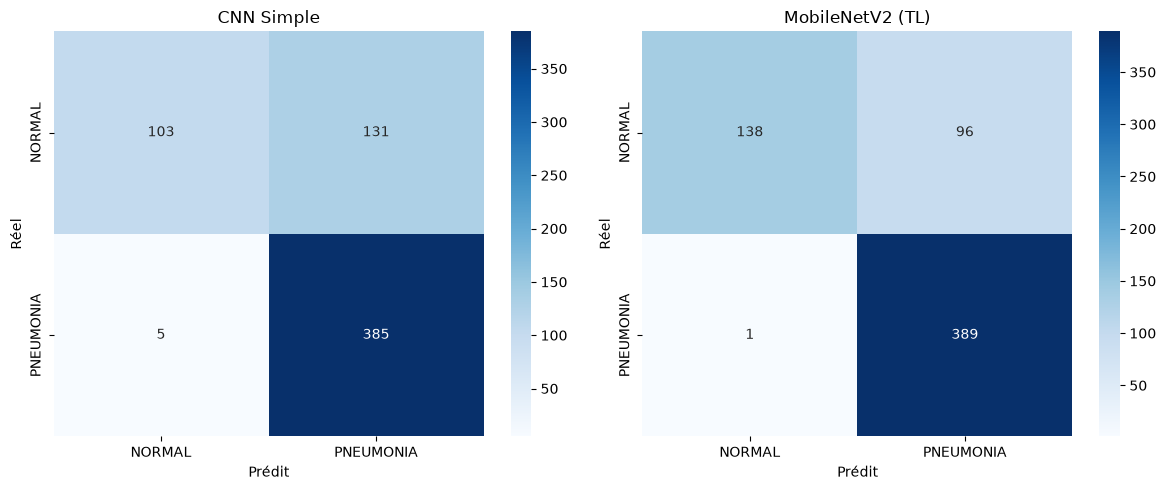

=== CNN Simple ===
              precision    recall  f1-score   support

      NORMAL       0.95      0.44      0.60       234
   PNEUMONIA       0.75      0.99      0.85       390

    accuracy                           0.78       624
   macro avg       0.85      0.71      0.73       624
weighted avg       0.82      0.78      0.76       624


=== MobileNetV2 (Transfer Learning) ===
              precision    recall  f1-score   support

      NORMAL       0.99      0.59      0.74       234
   PNEUMONIA       0.80      1.00      0.89       390

    accuracy                           0.84       624
   macro avg       0.90      0.79      0.81       624
weighted avg       0.87      0.84      0.83       624



In [3]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

# Prédictions
y_pred_cnn = (model_cnn.predict(X_test, verbose=0) > 0.5).astype(int).flatten()
y_pred_tl = (model_tl.predict(X_test_mnv2, verbose=0) > 0.5).astype(int).flatten()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, y_pred, title in zip(axes, [y_pred_cnn, y_pred_tl], ["CNN Simple", "MobileNetV2 (TL)"]):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", 
                xticklabels=["NORMAL", "PNEUMONIA"], 
                yticklabels=["NORMAL", "PNEUMONIA"], ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Prédit")
    ax.set_ylabel("Réel")

plt.tight_layout()
plt.show()

print("=== CNN Simple ===")
print(classification_report(y_test, y_pred_cnn, target_names=["NORMAL", "PNEUMONIA"]))

print("\n=== MobileNetV2 (Transfer Learning) ===")
print(classification_report(y_test, y_pred_tl, target_names=["NORMAL", "PNEUMONIA"]))

## Analyse des résultats

Les deux modèles obtiennent une excellente accuracy en validation (~97%) mais une 
performance nettement plus faible sur le test set (78% pour le CNN, 84% pour MobileNet).

La matrice de confusion révèle que cet écart provient presque uniquement de la classe 
NORMAL : les deux modèles ont un excellent recall sur PNEUMONIA (99-100%) mais un recall 
faible sur NORMAL (44% et 59%).

Deux causes probables :
1. Déséquilibre des classes en train (3294 PNEUMONIA vs 1140 NORMAL)
2. Distribution shift connu sur ce dataset Kaggle entre train et test

D'un point de vue clinique, ce biais reste "du bon côté" : les faux négatifs 
(pneumonie non détectée) sont très rares, ce qui limite le risque de retard de 
traitement, au prix d'un taux de faux positifs plus élevé.

MobileNetV2 (Transfer Learning) reste le meilleur modèle sur toutes les métriques.

=== MobileNetV2 (pondéré) ===
Test Accuracy: 0.8494
Test Loss: 0.4617


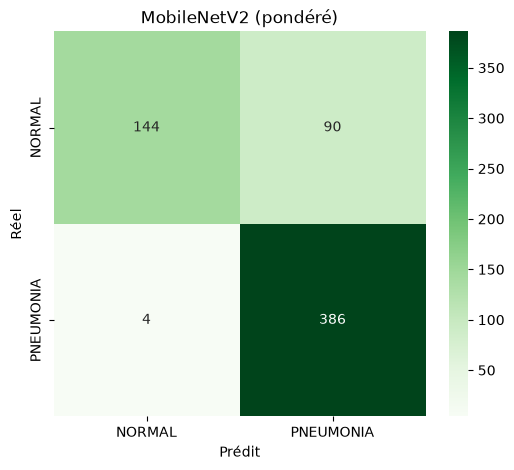

              precision    recall  f1-score   support

      NORMAL       0.97      0.62      0.75       234
   PNEUMONIA       0.81      0.99      0.89       390

    accuracy                           0.85       624
   macro avg       0.89      0.80      0.82       624
weighted avg       0.87      0.85      0.84       624



In [4]:
# Charger le 3ème modèle
model_tl_weighted = keras.models.load_model(os.path.join(MODELS_DIR, "model_v3_mobilenet_weighted.keras"))

# Évaluation globale
test_loss_w, test_acc_w = model_tl_weighted.evaluate(X_test_mnv2, y_test, verbose=0)
print(f"=== MobileNetV2 (pondéré) ===")
print(f"Test Accuracy: {test_acc_w:.4f}")
print(f"Test Loss: {test_loss_w:.4f}")

# Prédictions et matrice de confusion
y_pred_w = (model_tl_weighted.predict(X_test_mnv2, verbose=0) > 0.5).astype(int).flatten()

cm_w = confusion_matrix(y_test, y_pred_w)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_w, annot=True, fmt="d", cmap="Greens",
            xticklabels=["NORMAL", "PNEUMONIA"],
            yticklabels=["NORMAL", "PNEUMONIA"])
plt.title("MobileNetV2 (pondéré)")
plt.xlabel("Prédit")
plt.ylabel("Réel")
plt.show()

print(classification_report(y_test, y_pred_w, target_names=["NORMAL", "PNEUMONIA"]))

## Conclusion de l'évaluation

| Modèle | Test Accuracy | Recall NORMAL | Recall PNEUMONIA |
|---|---|---|---|
| CNN Simple | 78.2% | 44% | 99% |
| MobileNetV2 | 84.5% | 59% | 100% |
| MobileNetV2 (pondéré) | 84.9% | 62% | 99% |

La pondération des classes améliore légèrement le recall sur NORMAL (+3 points) et 
réduit significativement la loss (meilleure calibration), mais ne résout pas 
entièrement le problème. Cela confirme que l'écart de performance entre validation 
et test provient majoritairement d'un **distribution shift** entre les deux ensembles 
(différence de qualité/style d'image), un phénomène documenté sur ce dataset Kaggle, 
plutôt que du seul déséquilibre des classes.

**Modèle retenu : MobileNetV2 pondéré**, pour son meilleur compromis accuracy/loss/recall.

### Limites identifiées
- Distribution shift train/test non résolu
- Dataset limité en diversité (source unique)
- Modèle non validé cliniquement — usage strictement académique
- 